# EDA — risco de baixo peso ao nascer (SINASC, Pernambuco)

**G01 · Entrega E3.** Cada figura sustenta uma decisão de preparação ou de modelagem.

- **Dados:** população do modelo (gestação única com mês de início do pré-natal registrado), anos de
  **desenvolvimento (2019–2023)**. O ano de **teste (2024) não é explorado** aqui, para não influenciar
  nenhuma escolha com o conjunto que avalia o modelo no fim.
- **Origem das figuras:** as funções de `src/evaluation/eda.py`. Este notebook não tem lógica própria: as
  mesmas figuras são gravadas em `reports/figures/` pela etapa `eda` do pipeline
  (`python -m src.pipeline --config configs/base.yaml`), e os dados de cada uma em `reports/tables/`.
- **Pré-requisito:** `python -m src.pipeline --config configs/base.yaml --etapa dados`.
- Prevalências com intervalo de confiança de 95% (Wilson).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent  # notebooks/ -> pasta do grupo
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import carregar_config
from src.evaluation import eda

cfg = carregar_config(RAIZ / "configs" / "base.yaml")
df = eda.carregar_desenvolvimento(cfg)
alvo = df[cfg["dados"]["alvo"]]
print(f"{len(df):,} registros de desenvolvimento ({df['ANO'].min()}–{df['ANO'].max()}); "
      f"baixo peso: {alvo.sum():,} ({100 * alvo.mean():.2f}%)")


def mostrar(nome, funcao):
    """Gera a figura pela mesma função do pipeline, grava em reports/ e exibe o arquivo gravado."""
    fig, tabela = funcao(df, cfg)
    eda.salvar(fig, tabela, nome, cfg)
    plt.close(fig)
    display(Image(filename=str(RAIZ / cfg["saidas"]["figuras"] / f"figura-eda-{nome}.png")))
    return tabela


FIGURAS = dict(eda.FIGURAS)

585,505 registros de desenvolvimento (2019–2023); baixo peso: 40,760 (6.96%)


## 1. Desbalanceamento e tendência

[carregar] usando cache cache-sinasc-2015-2024-0c8c0fc8e95e0fd4.pkl


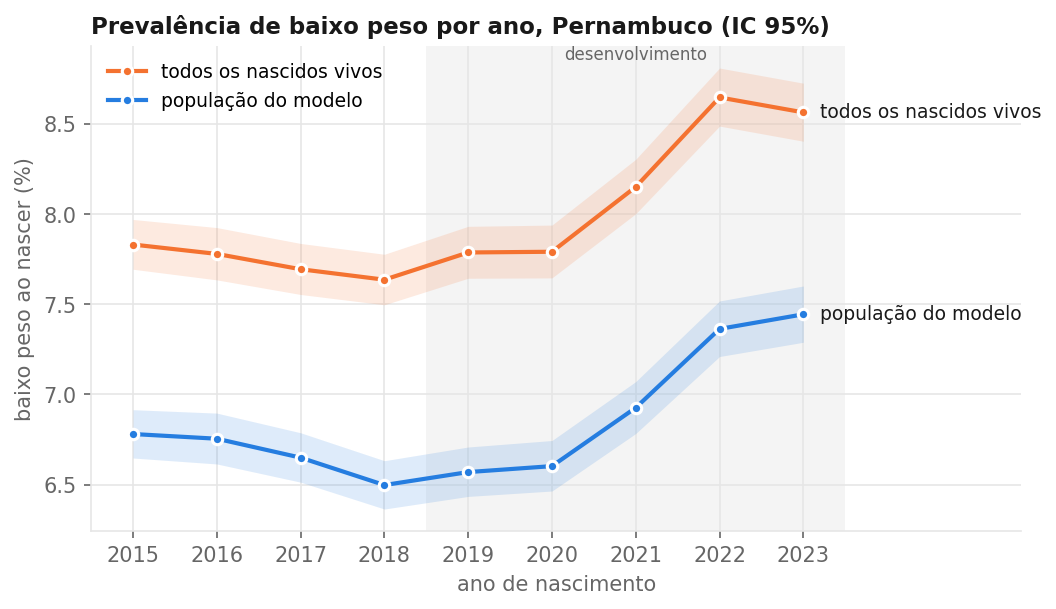

registros  baixo_peso  pct_baixo_peso  ic95_inf  \
grupo                   ano                                                     
todos os nascidos vivos 2015     144963       11352           7.831     7.694   
                        2016     130679       10165           7.779     7.635   
                        2017     135878       10455           7.694     7.554   
                        2018     138257       10557           7.636     7.497   
                        2019     133304       10380           7.787     7.644   
                        2020     128433       10006           7.791     7.646   
                        2021     126176       10285           8.151     8.002   
                        2022     117375       10150           8.647     8.488   
                        2023     116116        9944           8.564     8.404   
população do modelo     2015     135200        9166           6.780     6.647   
                        2016     122080        8245           6.754     6.614   
                        2017     127147        8454           6.649     6.513   
                        2018     130635        8487           6.497     6.364   
                        2019     125540        8247           6.569     6.434   
                        2020     121121        7997           6.602     6.464   
                        2021     119218        8257           6.926     6.783   
                        2022     110530        8138           7.363     7.210   
                        2023     109113        8122           7.444     7.289   

                              ic95_sup  
grupo                   ano             
todos os nascidos vivos 2015     7.970  
                        2016     7.925  
                        2017     7.837  
                        2018     7.777  
                        2019     7.932  
                        2020     7.939  
                        2021     8.304  
                        2022     8.810  
                        2023     8.726  
população do modelo     2015     6.915  
                        2016     6.896  
                        2017     6.787  
                        2018     6.632  
                        2019     6.708  
                        2020     6.744  
                        2021     7.071  
                        2022     7.518  
                        2023     7.601

In [2]:
mostrar("01-prevalencia-por-ano", FIGURAS["01-prevalencia-por-ano"])

**O que a figura mostra.** Na população do modelo, 6,57% dos nascidos vivos tiveram baixo peso em 2019
e 7,44% em 2023: cerca de 1 caso para cada 13. Entre todos os nascidos vivos, a prevalência é maior, porque
inclui os gêmeos, e sobe no mesmo período (7,79% → 8,56%). A alta começa em 2021 e continua dentro do
próprio período de desenvolvimento.

**Decisão.**
- **Métrica principal PR-AUC**, com folds estratificados pelo alvo. Com cerca de 7% de positivos, a
  acurácia de quem sempre responde "não" passaria de 93%.
- **Desbalanceamento tratado no modelo** (pesos de classe ou limiar escolhido na validação), sem
  reamostrar dados. A escolha fica para a E4.
- A tendência de alta confirma o **teste temporal em 2024**. Na E5, o desempenho também será reportado
  por ano, porque a prevalência de base muda de um ano para o outro.

## 2. Ausentes

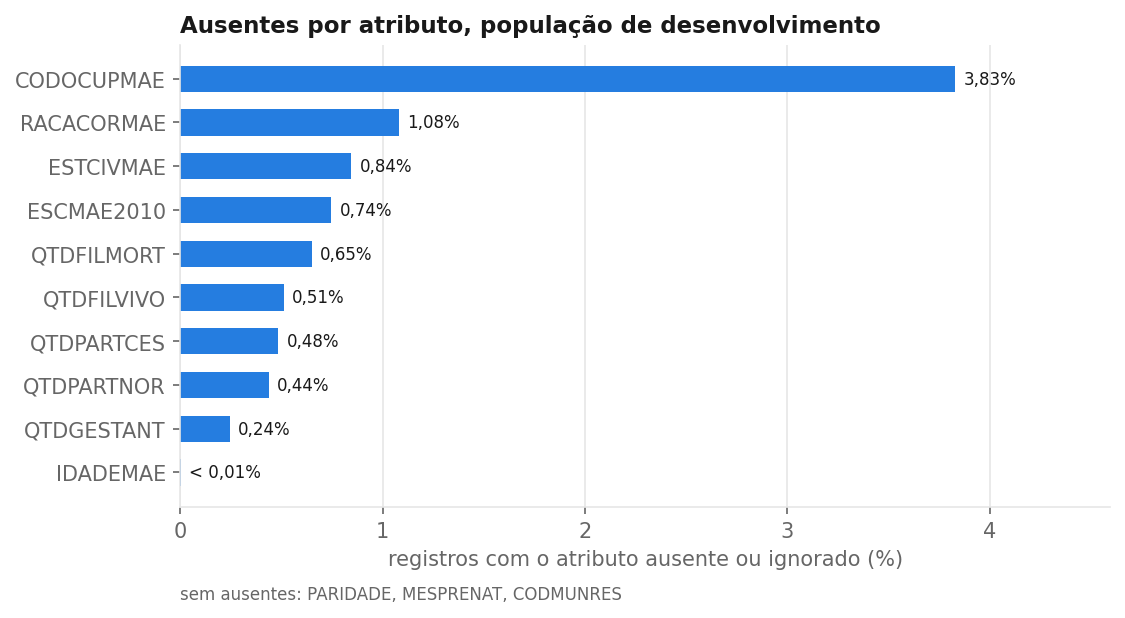

,pct_ausente,ausentes,pct_baixo_peso_ausente,pct_baixo_peso_presente
atributo,,,,
PARIDADE,0.000,0,NaN,6.962
MESPRENAT,0.000,0,NaN,6.962
CODMUNRES,0.000,0,NaN,6.962
IDADEMAE,0.002,12,8.333,6.961
QTDGESTANT,0.245,1437,5.358,6.965
QTDPARTNOR,0.436,2550,5.294,6.969
QTDPARTCES,0.483,2830,5.300,6.970
QTDFILVIVO,0.511,2992,5.749,6.968
QTDFILMORT,0.649,3800,5.421,6.972


In [3]:
mostrar("02-ausentes", FIGURAS["02-ausentes"])

**O que a figura mostra.** Nenhum atributo passa de 4% de ausentes. O maior índice é o da ocupação
(`CODOCUPMAE`, 3,83%). Os registros com dado ausente têm prevalência **menor** que a média: entre 5,0% e
5,8%, contra 6,96% (tabela abaixo da figura). O ausente não é aleatório.

**Decisão.**
- **Nenhum registro é descartado por ausência.** A perda seria pequena, mas tiraria justamente um grupo
  com risco diferente.
- **Atributos categóricos ausentes viram a categoria própria `ignorado`**, e não a moda. A moda jogaria
  esses registros num grupo com outra prevalência (a figura 6 mostra o mesmo padrão).
- **Idade da mãe ausente (12 registros)** recebe a mediana do treino de cada fold.
- **O histórico obstétrico passa a ser categórico** (figura 5), então o ausente também vira `ignorado`.
- A imputação fica dentro do `Pipeline`, ajustada só no treino de cada fold.

## 3. Idade da mãe

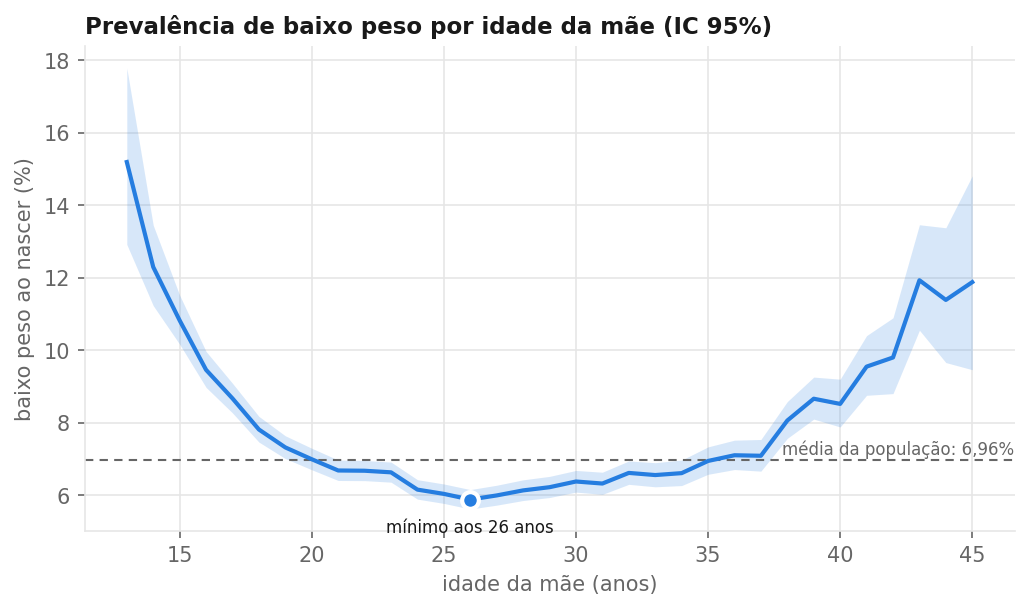

,registros,baixo_peso,pct_baixo_peso,ic95_inf,ic95_sup
IDADEMAE,,,,,
13,836,127,15.191,12.918,17.783
14,3375,415,12.296,11.231,13.447
15,8112,878,10.823,10.166,11.518
16,13456,1273,9.460,8.977,9.967
17,18220,1580,8.672,8.272,9.089
18,22073,1725,7.815,7.468,8.176
19,26457,1937,7.321,7.014,7.641
20,28447,1990,6.995,6.705,7.298
21,30260,2023,6.685,6.409,6.972


In [4]:
mostrar("03-idade-mae", FIGURAS["03-idade-mae"])

**O que a figura mostra.** Uma curva em U: 15,19% de baixo peso aos 13 anos, mínimo de 5,88% aos 26 e
8,52% aos 40, subindo depois disso, com intervalos mais largos porque há poucas mães nessas idades.

**Decisão.**
- **A idade entra com splines** (5 nós, grau 3; `preprocessamento.idade_splines` no config). Um termo
  linear obrigaria o modelo linear da E4 a escolher entre o risco das adolescentes e o das mães mais
  velhas. Os nós são ajustados só no treino de cada fold.
- Modelos de árvore captam o U sem transformação. Os splines não os prejudicam.

## 4. Mês de início do pré-natal

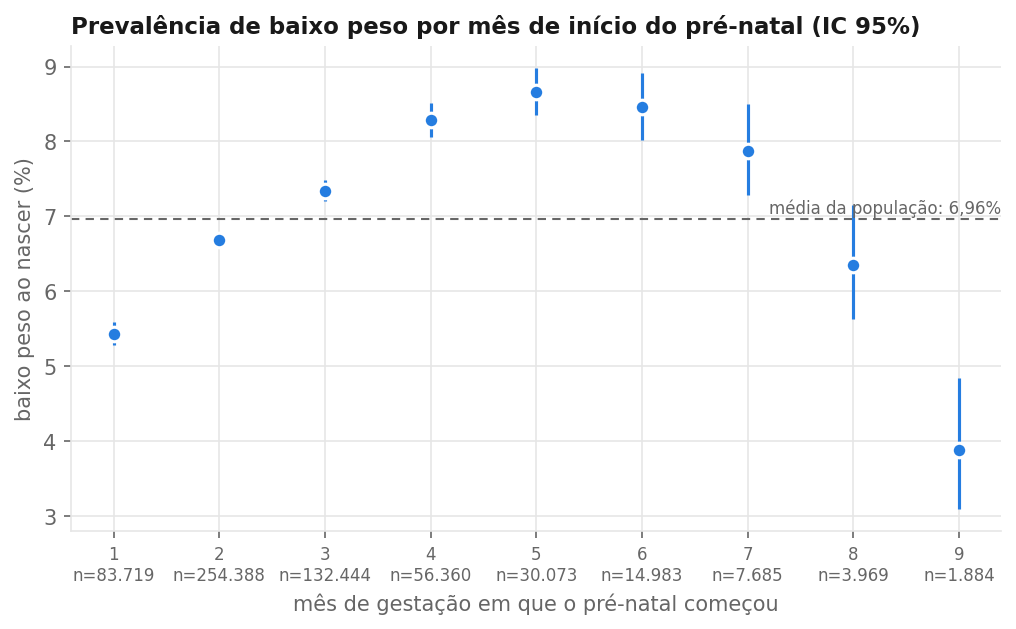

,registros,baixo_peso,pct_baixo_peso,ic95_inf,ic95_sup
MESPRENAT,,,,,
1,83719,4549,5.434,5.282,5.589
2,254388,17014,6.688,6.592,6.786
3,132444,9727,7.344,7.205,7.486
4,56360,4668,8.282,8.058,8.513
5,30073,2605,8.662,8.350,8.985
6,14983,1267,8.456,8.021,8.912
7,7685,605,7.872,7.291,8.496
8,3969,252,6.349,5.632,7.151
9,1884,73,3.875,3.093,4.844


In [5]:
mostrar("04-mes-inicio-prenatal", FIGURAS["04-mes-inicio-prenatal"])

**O que a figura mostra.** A relação **não é monotônica**. A prevalência sobe de 5,43% (início no mês 1)
para 8,66% (mês 5) e cai para 3,88% (mês 9).
- **A subida** é compatível com o efeito esperado de começar o acompanhamento tarde.
- **A queda nos meses 8 e 9** tem outra origem: só começa o pré-natal nesses meses a gestação que chegou
  até eles, e ela raramente termina prematura.

Isso **não é vazamento**. Na captação, o mês em que a gestante está é conhecido, e é exatamente essa a
informação que o modelo recebe. Mas também mostra que, para quem chega no fim da gestação, o modelo tem
pouco a acrescentar.

**Decisão.**
- **`MESPRENAT` entra como categoria** (um indicador por mês), e não como número: uma reta não representa
  uma relação que sobe e depois desce.
- Na E5, o desempenho será olhado também por mês de captação.

## 5. Histórico obstétrico

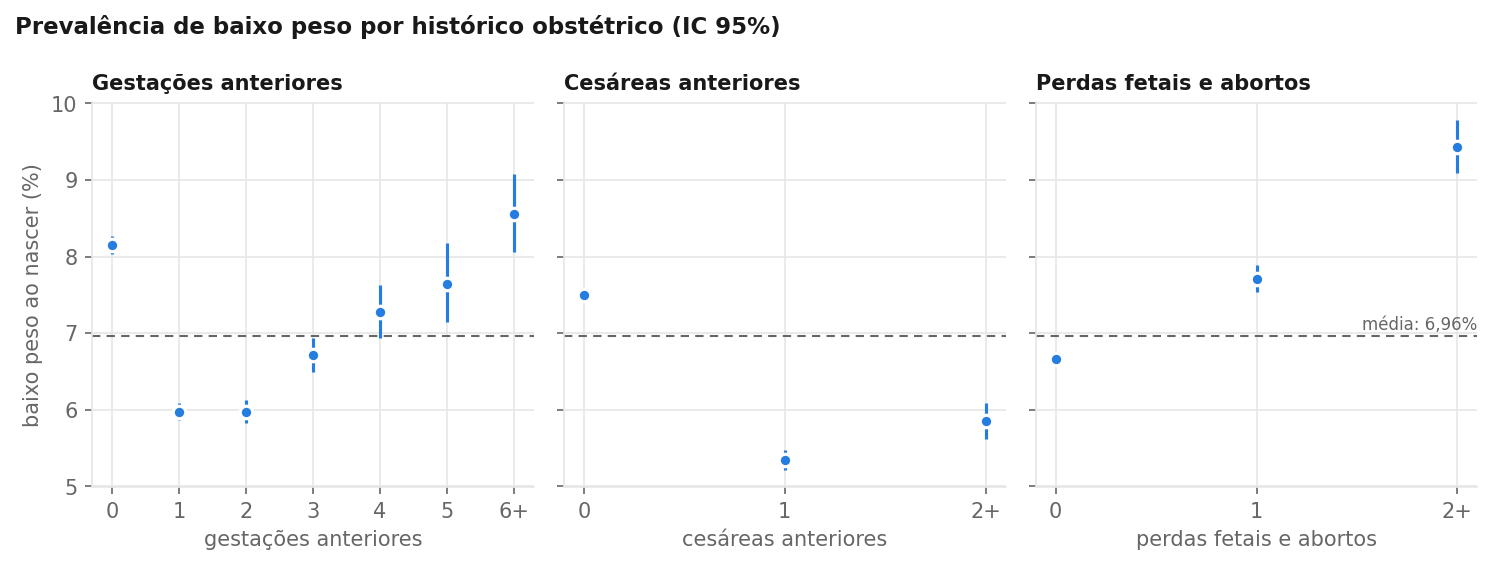

registros  baixo_peso  pct_baixo_peso  ic95_inf  ic95_sup
atributo   valor                                                           
QTDGESTANT 0         214943       17517           8.150     8.035     8.266
           1         179151       10703           5.974     5.865     6.085
           2         100783        6025           5.978     5.833     6.126
           3          47308        3175           6.711     6.489     6.940
           4          21453        1561           7.276     6.936     7.632
           5          10086         771           7.644     7.142     8.179
           6+         11781        1008           8.556     8.064     9.075
QTDPARTCES 0         430677       32292           7.498     7.420     7.577
           1         117131        6263           5.347     5.220     5.477
           2+         37697        2205           5.849     5.617     6.091
QTDFILMORT 0         465366       31018           6.665     6.594     6.737
           1          92324        7118           7.710     7.539     7.884
           2+         27815        2624           9.434     9.096     9.783

In [6]:
mostrar("05-historico-obstetrico", FIGURAS["05-historico-obstetrico"])

**O que a figura mostra.**
- **Gestações anteriores:** relação em U. A primeira gestação tem 8,15% de baixo peso, quem já teve uma
  ou duas tem cerca de 5,97%, e a partir daí sobe até 8,56% em "6+".
- **Cesáreas anteriores:** "nenhuma" tem 7,50% (grupo que inclui as primigestas), e "uma" tem 5,35%.
- **Perdas fetais e abortos:** crescimento monotônico (6,67% → 7,71% → 9,43%).
- As caudas são raras: o percentil 99 fica em 6 gestações, 5 partos vaginais, 5 filhos vivos, 2 cesáreas
  e 2 perdas.

**Decisão.**
- **Cada contagem é limitada ao percentil 99 do desenvolvimento** e tratada como categoria ("0", "1", …,
  "N+"; tetos em `preprocessamento.historico_teto`). Isso representa as relações em U sem criar
  categorias com poucos casos.
- Os tetos vêm do desenvolvimento. O teste não é usado.

## 6. Perfil da mãe

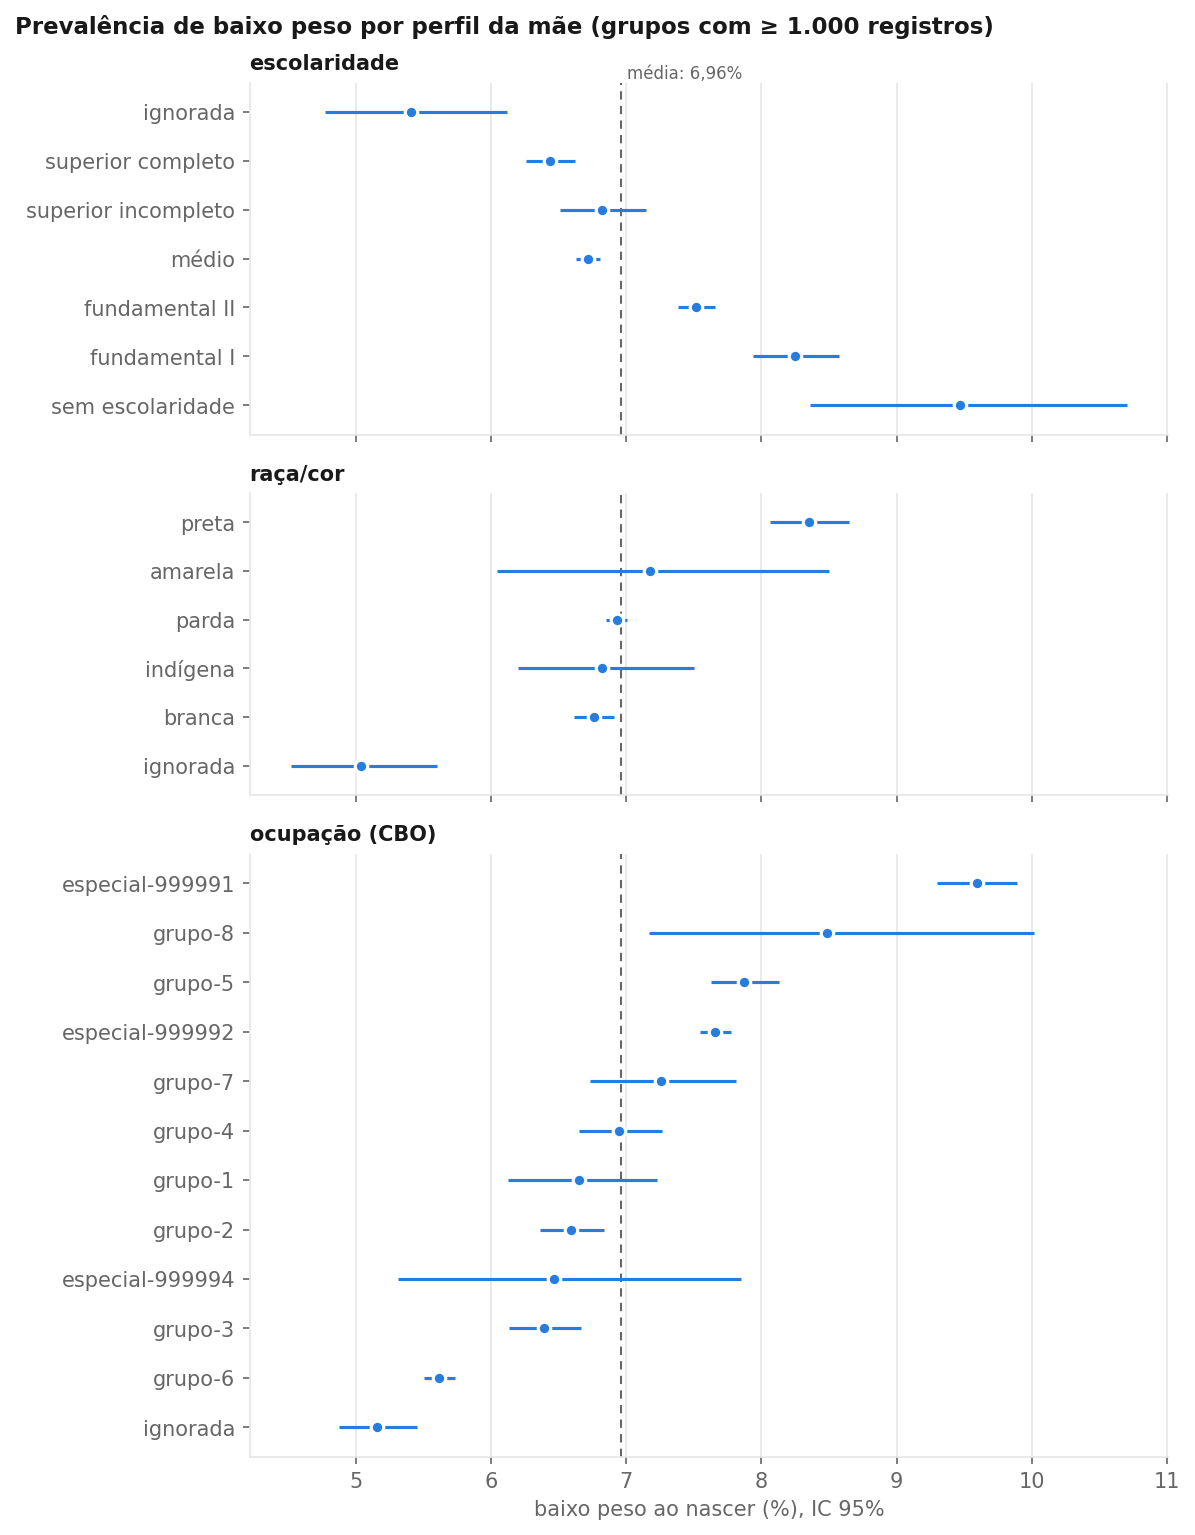

registros  baixo_peso  pct_baixo_peso  \
bloco          categoria                                                    
escolaridade   sem escolaridade          2409         228           9.465   
               fundamental I            28766        2373           8.249   
               fundamental II          144480       10863           7.519   
               médio                   311458       20914           6.715   
               superior incompleto      24083        1643           6.822   
               superior completo        69945        4503           6.438   
               ignorada                  4364         236           5.408   
raça/cor       ignorada                  6313         318           5.037   
               branca                  110532        7471           6.759   
               indígena                  5774         394           6.824   
               parda                   426204       29534           6.930   
               amarela                   1700         122           7.176   
               preta                    34982        2921           8.350   
ocupação (CBO) ignorada                 22430        1157           5.158   
               grupo-6                 155130        8718           5.620   
               grupo-3                  32427        2073           6.393   
               especial-999994           1453          94           6.469   
               grupo-2                  42571        2807           6.594   
               grupo-1                   7830         521           6.654   
               grupo-4                  26524        1843           6.948   
               grupo-7                   8848         642           7.256   
               especial-999992         203264       15565           7.658   
               grupo-5                  44697        3519           7.873   
               grupo-8                   1485         126           8.485   
               especial-999991          37758        3621           9.590   

                                    ic95_inf  ic95_sup  
bloco          categoria                                
escolaridade   sem escolaridade        8.359    10.699  
               fundamental I           7.937     8.573  
               fundamental II          7.384     7.656  
               médio                   6.628     6.803  
               superior incompleto     6.511     7.148  
               superior completo       6.258     6.622  
               ignorada                4.775     6.119  
raça/cor       ignorada                4.525     5.605  
               branca                  6.613     6.909  
               indígena                6.202     7.503  
               parda                   6.854     7.006  
               amarela                 6.044     8.502  
               preta                   8.065     8.644  
ocupação (CBO) ignorada                4.876     5.455  
               grupo-6                 5.506     5.736  
               grupo-3                 6.132     6.664  
               especial-999994         5.316     7.852  
               grupo-2                 6.362     6.833  
               grupo-1                 6.123     7.227  
               grupo-4                 6.649     7.261  
               grupo-7                 6.734     7.815  
               especial-999992         7.543     7.774  
               grupo-5                 7.627     8.126  
               grupo-8                 7.172    10.011  
               especial-999991         9.297     9.891

In [7]:
mostrar("06-perfil-mae", FIGURAS["06-perfil-mae"])

**O que a figura mostra.**
- **Escolaridade:** gradiente nítido, de 9,47% (sem escolaridade) a 6,44% (superior completo).
- **Raça/cor:** mães pretas têm 8,35% de baixo peso, contra 6,76% de brancas e 6,93% de pardas.
- **Ocupação:** varia de 5,62% no grande grupo 6 da CBO (agropecuária) a 9,59% no código especial
  `999991`. Os códigos especiais `9999xx` do SINASC se comportam de forma diferente entre si. O
  significado de cada um não consta no dicionário oficial.
- **"Ignorado"** tem a menor prevalência nos três blocos (5,0% a 5,4%).

**Decisão.**
- **Os três atributos entram com one-hot.** Na ocupação, os códigos especiais ficam como categorias
  próprias, e não junto do grande grupo 9 da CBO, que seria o resultado de usar só o primeiro dígito.
- **"Ignorado" continua como categoria própria** (confirma a decisão da figura 2).
- As diferenças por raça/cor e escolaridade tornam **obrigatória a análise de desempenho por subgrupo**
  na E5 (RQ-ÉT-02). Um limiar único pode dar recall diferente para cada grupo.

## Resumo das decisões

| Figura | Achado | Decisão (onde está implementada) |
| ------ | ------ | -------------------------------- |
| 1 | cerca de 7% de positivos e alta a partir de 2021 | PR-AUC, folds estratificados, desbalanceamento tratado no modelo; teste temporal em 2024 (`configs/base.yaml`) |
| 2 | menos de 4% de ausentes, com prevalência menor | nenhum registro descartado; categórico → `ignorado`, numérico → mediana, dentro do `Pipeline` (`src/features/preprocessamento.py`) |
| 3 | idade em U | splines na idade (`preprocessamento.idade_splines`) |
| 4 | mês de início do pré-natal não monotônico | `MESPRENAT` categórico (`src/features/construcao.py`) |
| 5 | histórico em U e caudas raras | contagens com teto no percentil 99, como categorias (`preprocessamento.historico_teto`) |
| 6 | gradientes por escolaridade, raça/cor e ocupação | one-hot, códigos especiais separados e análise por subgrupo na E5 |

As decisões também estão registradas em `docs/decisoes-tecnicas.md`, com a alternativa rejeitada.